In [14]:
# Install the PySpark package for working with large datasets in a distributed environment
!pip install pyspark

In [15]:
from google.colab import files

# Open the file picker dialog to let the user upload student_performance.csv manually
uploaded = files.upload()  # Select student_performance.csv

Saving student_performance.csv to student_performance (1).csv


In [16]:
from pyspark.sql import SparkSession

# Initialize a local SparkSession for runnning Spark operations in Google Colab
spark = (
    SparkSession.builder
    .appName("Student Performance Analytics")
    .master("local[*]")
    .getOrCreate()
)

# Define the path of our uploaded dataset
csv_path = "student_performance.csv"

# Load the CSV dataset into a PySpark DataFrame with header detection and automatic type schema inference
df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .csv(csv_path)
)

# Print basic summary information of the loaded data
print("Number of records:", df.count())
df.printSchema()
df.show(5)

Number of records: 500
root
 |-- student_id: string (nullable = true)
 |-- study_hours_per_day: double (nullable = true)
 |-- attendance_percentage: integer (nullable = true)
 |-- previous_exam_score: integer (nullable = true)
 |-- exam_score: integer (nullable = true)
 |-- passed: integer (nullable = true)

+----------+-------------------+---------------------+-------------------+----------+------+
|student_id|study_hours_per_day|attendance_percentage|previous_exam_score|exam_score|passed|
+----------+-------------------+---------------------+-------------------+----------+------+
|      S001|                5.3|                   56|                 65|        77|     1|
|      S002|                1.3|                   89|                 41|        63|     1|
|      S003|                4.9|                   57|                 33|        73|     1|
|      S004|                5.0|                   90|                 55|        84|     1|
|      S005|                5.9|       

In [17]:
from pyspark.sql import functions as F

# Loop through all columns to count missing values (either standard SQL Nulls or empty strings)
for column in df.columns:
    missing_count = df.filter(
        F.col(column).isNull() | (F.trim(F.col(column).cast("string")) == "")
    ).count()
    print(f"{column}: {missing_count} missing values")

# Count the total number of exact duplicate rows in the raw dataset
print("Duplicate rows:", df.count() - df.dropDuplicates().count())

student_id: 0 missing values
study_hours_per_day: 0 missing values
attendance_percentage: 0 missing values
previous_exam_score: 0 missing values
exam_score: 0 missing values
passed: 0 missing values
Duplicate rows: 0


In [18]:
from pyspark.sql.types import (
    DoubleType,
    IntegerType,
    StringType
)

# Clean the dataset by removing duplicate student records, dropping nulls in critical fields,
# and ensuring all feature columns have explicit and appropriate numeric data types
clean_df = (
    df.dropDuplicates(["student_id"])
      .dropna(subset=[
          "study_hours_per_day",
          "attendance_percentage",
          "previous_exam_score",
          "passed"
      ])
      .withColumn("study_hours_per_day", F.col("study_hours_per_day").cast(DoubleType()))
      .withColumn("attendance_percentage", F.col("attendance_percentage").cast(IntegerType()))
      .withColumn("previous_exam_score", F.col("previous_exam_score").cast(IntegerType()))
      .withColumn("exam_score", F.col("exam_score").cast(IntegerType()))
      .withColumn("passed", F.col("passed").cast(IntegerType()))
)

# Verify dataset count and view samples after applying our cleaning pipelines
print("Records after cleaning:", clean_df.count())
clean_df.show(5)

Records after cleaning: 500
+----------+-------------------+---------------------+-------------------+----------+------+
|student_id|study_hours_per_day|attendance_percentage|previous_exam_score|exam_score|passed|
+----------+-------------------+---------------------+-------------------+----------+------+
|      S066|                4.4|                   71|                 56|        79|     1|
|      S394|                5.3|                   78|                 62|        87|     1|
|      S032|                1.3|                   95|                 68|        56|     1|
|      S076|                6.1|                   64|                 64|        99|     1|
|      S320|                2.6|                   98|                 92|        83|     1|
+----------+-------------------+---------------------+-------------------+----------+------+
only showing top 5 rows


In [19]:
# Calculate overall cohort statistics including average score, study hours, and attendance
clean_df.select(
    F.count("*").alias("student_count"),
    F.round(F.avg("exam_score"), 2).alias("average_exam_score"),
    F.round(F.avg("study_hours_per_day"), 2).alias("average_study_hours"),
    F.round(F.avg("attendance_percentage"), 2).alias("average_attendance")
).show()

+-------------+------------------+-------------------+------------------+
|student_count|average_exam_score|average_study_hours|average_attendance|
+-------------+------------------+-------------------+------------------+
|          500|             75.49|               4.31|             78.45|
+-------------+------------------+-------------------+------------------+



In [20]:
# Register the PySpark DataFrame as a temporary view to enable execution of SQL queries
clean_df.createOrReplaceTempView("students")

# Execute a Spark SQL query to compare academic and behavioral metrics between students who passed and those who did not
pass_summary = spark.sql("""
    SELECT
        passed,
        COUNT(*) AS student_count,
        ROUND(AVG(exam_score), 2) AS average_exam_score,
        ROUND(AVG(study_hours_per_day), 2) AS average_study_hours,
        ROUND(AVG(attendance_percentage), 2) AS average_attendance
    FROM students
    GROUP BY passed
    ORDER BY passed
""")

pass_summary.show()

+------+-------------+------------------+-------------------+------------------+
|passed|student_count|average_exam_score|average_study_hours|average_attendance|
+------+-------------+------------------+-------------------+------------------+
|     0|           23|             44.43|               1.43|             72.17|
|     1|          477|             76.99|               4.45|             78.75|
+------+-------------+------------------+-------------------+------------------+



In [21]:
# Group the dataset based on daily study hours to analyze performance differences among the cohorts
study_summary = (
    clean_df
    .withColumn(
        "study_hours_group",
        F.when(F.col("study_hours_per_day") < 2, "Under 2 hours")
         .when(F.col("study_hours_per_day") < 4, "2 to under 4 hours")
         .when(F.col("study_hours_per_day") < 6, "4 to under 6 hours")
         .otherwise("6 or more hours")
    )
    .groupBy("study_hours_group")
    .agg(
        F.count("*").alias("student_count"),
        F.round(F.avg("exam_score"), 2).alias("average_exam_score")
    )
)

study_summary.show()

+------------------+-------------+------------------+
| study_hours_group|student_count|average_exam_score|
+------------------+-------------+------------------+
|     Under 2 hours|          103|             60.03|
|2 to under 4 hours|          124|             69.85|
|   6 or more hours|          146|             88.65|
|4 to under 6 hours|          127|             78.42|
+------------------+-------------+------------------+



In [22]:
from pyspark.ml import Pipeline
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import (
    BinaryClassificationEvaluator,
    MulticlassClassificationEvaluator
)
from pyspark.ml.feature import VectorAssembler

# Define behavioral features to predict whether a student passes
feature_columns = [
    "study_hours_per_day",
    "attendance_percentage",
    "previous_exam_score"
]

# Assemble numeric features into a single vector column for PySpark ML compatibility
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features"
)

# Configure a Logistic Regression classifier to predict the 'passed' target label
logistic_regression = LogisticRegression(
    featuresCol="features",
    labelCol="passed",
    maxIter=50
)

# Chain assembler and model stages together inside an ML Pipeline
pipeline = Pipeline(stages=[assembler, logistic_regression])

# Split data into train (80%) and test (20%) sets to ensure model generalization
train_df, test_df = clean_df.randomSplit([0.8, 0.2], seed=42)

# Train the pipeline model on the training set
model = pipeline.fit(train_df)

# Use the trained model to run inference/generate predictions on the test set
predictions = model.transform(test_df)

# Display sample predictions along with their estimated class probabilities
predictions.select(
    "student_id",
    "passed",
    "prediction",
    "probability"
).show(10, truncate=False)

+----------+------+----------+------------------------------------------+
|student_id|passed|prediction|probability                               |
+----------+------+----------+------------------------------------------+
|S003      |1     |1.0       |[0.021790863366226848,0.9782091366337732] |
|S007      |1     |1.0       |[2.791358198914703E-4,0.9997208641801085] |
|S009      |1     |1.0       |[0.16783269625759606,0.832167303742404]   |
|S014      |1     |1.0       |[6.230531939280145E-5,0.9999376946806072] |
|S020      |1     |1.0       |[0.03554922280164987,0.9644507771983502]  |
|S024      |1     |1.0       |[4.021565399136327E-5,0.9999597843460086] |
|S030      |1     |1.0       |[0.012600552944694378,0.9873994470553056] |
|S036      |1     |1.0       |[1.7602743940356887E-5,0.9999823972560596]|
|S046      |1     |1.0       |[0.0019869936646207107,0.9980130063353793]|
|S047      |1     |1.0       |[1.6725699201290636E-5,0.9999832743007987]|
+----------+------+----------+--------

In [23]:
# Instantiate metrics evaluators to measure accuracy, F1-score, and Area Under ROC curve on the predictions
accuracy_evaluator = MulticlassClassificationEvaluator(
    labelCol="passed",
    predictionCol="prediction",
    metricName="accuracy"
)

f1_evaluator = MulticlassClassificationEvaluator(
    labelCol="passed",
    predictionCol="prediction",
    metricName="f1"
)

area_under_roc_evaluator = BinaryClassificationEvaluator(
    labelCol="passed",
    rawPredictionCol="rawPrediction",
    metricName="areaUnderROC"
)

# Compute and display test metrics to evaluate classification quality
print("Accuracy:", round(accuracy_evaluator.evaluate(predictions), 3))
print("F1 score:", round(f1_evaluator.evaluate(predictions), 3))
print("Area under ROC:", round(area_under_roc_evaluator.evaluate(predictions), 3))

Accuracy: 1.0
F1 score: 1.0
Area under ROC: 1.0


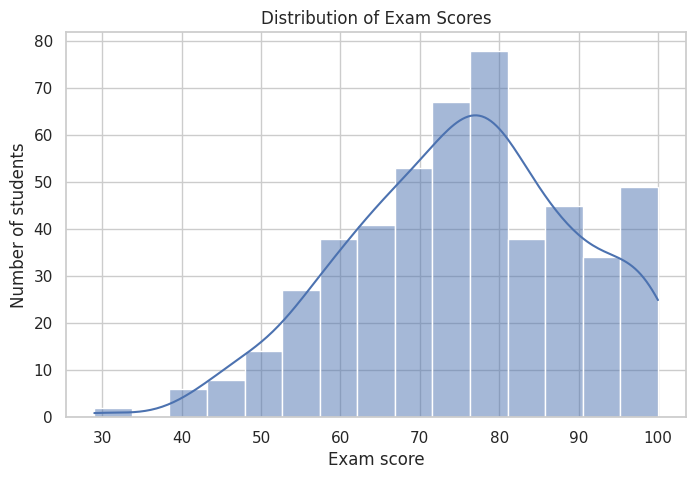

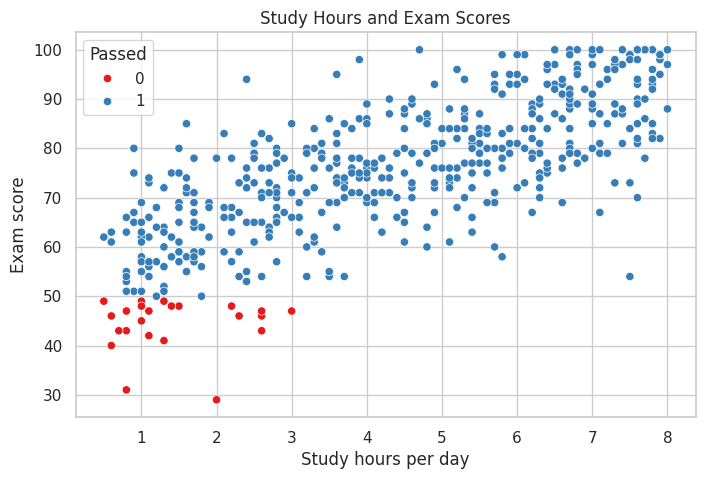

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# Convert selected columns to a Pandas DataFrame for plotting visualization
plot_df = clean_df.select(
    "study_hours_per_day",
    "attendance_percentage",
    "exam_score",
    "passed"
).toPandas()

sns.set_theme(style="whitegrid")

# Plot 1: Histogram showing the distribution of exam scores
plt.figure(figsize=(8, 5))
sns.histplot(data=plot_df, x="exam_score", bins=15, kde=True)
plt.title("Distribution of Exam Scores")
plt.xlabel("Exam score")
plt.ylabel("Number of students")
plt.show()

# Plot 2: Scatter plot analyzing correlation between study hours and exam scores, color-coded by passing status
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_df,
    x="study_hours_per_day",
    y="exam_score",
    hue="passed",
    palette="Set1"
)
plt.title("Study Hours and Exam Scores")
plt.xlabel("Study hours per day")
plt.ylabel("Exam score")
plt.legend(title="Passed")
plt.show()

**Distribution of Exam Scores**

The histogram shows how the students’ exam scores are spread across the dataset. Most scores fall between 60 and 90, with the highest concentration around 70 to 80. Only a few students scored below 50. Overall, the scores tend to be in the middle to higher range.

**Study Hours and Exam Scores**
Each dot represents one student. The graph shows a general upward pattern: students who study more hours per day often have higher exam scores. Blue dots represent students who passed, while red dots represent students who did not pass. There are exceptions, so study hours alone do not determine a student’s score.

**Note**: These charts use a synthetic dataset created for this project, so the patterns are for demonstration and should not be treated as findings about real students.

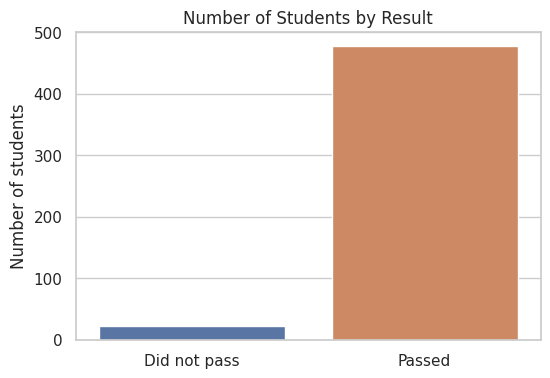

In [25]:
# Aggregate the count of passed vs did not pass outcomes and convert to Pandas for visualization
pass_counts = (
    clean_df.groupBy("passed")
    .count()
    .orderBy("passed")
    .toPandas()
)

# Map numeric labels to user-friendly text descriptions
pass_counts["result"] = pass_counts["passed"].map({
    0: "Did not pass",
    1: "Passed"
})

# Create a bar chart showing the final balance of student results
plt.figure(figsize=(6, 4))
sns.barplot(data=pass_counts, x="result", y="count", hue="result", legend=False)
plt.title("Number of Students by Result")
plt.xlabel("")
plt.ylabel("Number of students")
plt.show()

**Number of Students by Result**

This bar chart compares the number of students who passed with the number who did not pass. In this dataset, most students passed, while a much smaller number did not. This means the classes are imbalanced, with many more passing examples than failing examples.

The data is synthetic, so this chart demonstrates how to visualize pass/fail counts rather than describing a real student group.

In [26]:
# Cleanly close and release the Spark session resource
spark.stop()